In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## List of Functions Defined in Program

1.   ```daily_energy()```

        **Input**: UA

        **Output**: daily_non_HVAC, daily_HVAC

2.   ```error()```

      **Input**: UA

      **Output**: error = (billed annual energy) - (estimated annual non-HVAC) - (estimated annual HVAC)
      
  $$
  error = |\sum(\texttt{daily_total})-\sum(\texttt{non_HVAC})-\sum(\texttt{HVAC})|
  \\
  $$

3.   ```plot_daily_all()```
      
      **Input**: UA

      **Output**: Plots daily energy for BAU gas, BAU elec, non-HVAC and HVAC on one plot

4.   ```plot_daily_total()```

      **Input**: UA

      **Output**: Plots total gas+elec billed energy + non-HVAC+HVAC energy per day on one plot; used to visually see error

5.   ```dayvals()```
     
     **Input**: date,activity;
     $$ \texttt{date} \in [0,364]; \texttt{  activity} \in \texttt{{"high","low"}} $$
     
     **Output**: the "heat values" for that day of the year; heat values are defined in our Excel and under the "Heat Schedule" section.
     
6.   ```fracheat()```
      
      **Input**: daily_energy_array, activity; daily_energy_array is the energy array that you want to split into hourly data. activity is as defined above and determines which schedule the hourly data follows.
      
      **Output**: an array of length 8760 - the energy usage of every hour in the year.
7.   ```def()```
      **Input**:
      **Output**:


In [ ]:
# Define constants (initial guess)
# Won't optimize these:
heating_balance_point = 60
cooling_balance_point = 70
cooling_coef = 1.2

gaseff = 0.8
eleceff = 0.95

# Define weekly schedule
days = np.linspace(0,364,365)
hours = np.linspace(0,8759,8760) # hours of year

In [ ]:
# Define Billing Data
# Natural gas bills in therms * efficiency
jan_daily_gas = np.hstack([np.full(7, 9.31), np.full(31-7, 9.35)]) * gaseff
feb_daily_gas = np.full(28,9.35) *gaseff
mar_daily_gas = np.full(31,9.31) *gaseff
apr_daily_gas = np.full(30,8)*gaseff
may_daily_gas = np.full(31,4.5)*gaseff
jun_daily_gas = np.full(30,0.5)*gaseff
jul_daily_gas = np.full(31,0.2)*gaseff
aug_daily_gas = np.full(31,0.1)*gaseff
sep_daily_gas = np.full(30,0.35)*gaseff
oct_daily_gas = np.hstack([np.full(4,0.35),np.full(31-4,1.36)])*gaseff
nov_daily_gas = np.hstack([np.full(5,1.36),np.full(30-5,9.93)])*gaseff
dec_daily_gas = np.hstack([np.full(6,9.93),np.full(31-6,10.51)])*gaseff

# Electricity Bills in kWh and convert using efficiency
#to the amount of energy going into building
jan_daily_elec=np.full(31,43.91) * eleceff
feb_daily_elec=np.full(28,43.91)* eleceff
mar_daily_elec=np.full(31,30)* eleceff
apr_daily_elec=np.full(30,30)* eleceff
may_daily_elec=np.full(31,17.96)* eleceff
jun_daily_elec=np.full(30,17.96)* eleceff
jul_daily_elec=np.full(31,6.26)* eleceff
aug_daily_elec=np.full(31,6.26)* eleceff
sep_daily_elec=np.full(30,17.99)* eleceff
oct_daily_elec=np.full(31,17.99)* eleceff
nov_daily_elec=np.full(30,43.97)* eleceff
dec_daily_elec=np.full(31,43.97)* eleceff


daily_gas = np.hstack([jan_daily_gas, feb_daily_gas, mar_daily_gas, apr_daily_gas, may_daily_gas, jun_daily_gas, jul_daily_gas, aug_daily_gas, sep_daily_gas, oct_daily_gas, nov_daily_gas, dec_daily_gas]) * 29.3001
daily_elec = np.hstack([jan_daily_elec, feb_daily_elec, mar_daily_elec, apr_daily_elec, may_daily_elec, jun_daily_elec, jul_daily_elec, aug_daily_elec, sep_daily_elec, oct_daily_elec, nov_daily_elec, dec_daily_elec])
daily_total = daily_gas + daily_elec

In [ ]:
(np.max(daily_gas) + np.max(daily_elec))

np.float64(288.1267408)

## Temperature Data

In [ ]:
# Replace 'path/to/your/file.csv' with the path you copied in Step 2
from google.colab import drive
drive.mount('/content/drive')

file_path = 'drive/MyDrive/Capstone/tempdata.csv'
df1 = pd.read_csv(file_path)
data = df1.to_numpy()

tmax = data[:,1]
tmin = data[:,2]
tav = np.array((tmax + tmin) / 2)



Mounted at /content/drive


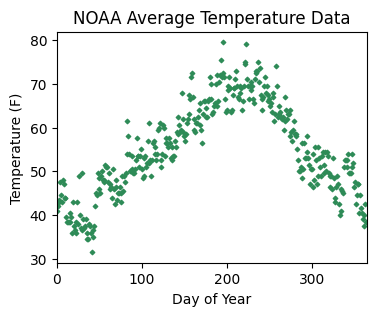

In [ ]:
plt.figure(figsize=(4, 3))
plt.scatter(days,tav,marker ='D', s = 5, color = "seagreen")
plt.title('NOAA Average Temperature Data')
plt.xlabel('Day of Year')
plt.ylabel('Temperature (F)')
plt.xlim(0,365)
plt.show()


# Steps

1.   Import daily averages on gas and electricity usage. Convert to kWh.
2.   Assume non-HVAC energy = minimum daily energy usage.
3.   HVAC energy = UA*[temp difference]
4.   Plot daily average and estimated data for gas and elec all on one graph.



# Graph Daily Energy Usage with Billing Average and Estimated Values



In [ ]:

def daily_energy(UA, cooling, activity):
  heating_deg_daily = np.maximum(heating_balance_point - tav, 0)
  # heat_deg = maximum of heating balance point - t_av vs. 0 (e.i. heating is on if outside temperature is cooler than balance point)
  if cooling == "T":
    cooling_deg_daily = np.maximum(tav - cooling_balance_point, 0)
    # cooling turns on if outisde temperature is warmer than balance point
  else:
    cooling_deg_daily  = 0

  # scale up non-hvac during high activity
  if activity == "high":
    coef = activity_coef
  else:
    coef = 1

  # Define constants + assumed base values
  daily_non_HVAC = np.full(365,np.min(daily_total)) * coef
  # non-HVAC = minimum total energy used for any given day of year

  daily_HVAC = UA * (heating_deg_daily+ (cooling_coef * cooling_deg_daily))

  return daily_non_HVAC, daily_HVAC

def error(UA): # not used since billing data is not good
  non_HVAC, HVAC = daily_energy(UA,"F", "low")
  error = np.abs(np.sum(daily_total)-np.sum(non_HVAC)-np.sum(HVAC))
  return error

In [ ]:
from scipy.optimize import minimize

result = minimize(error,12)
UA_opt = result.x
print(UA_opt)

[18.73760852]


# UA from Heat Pump Sizing
The UA was found to be 37.836 kWh/(day-F) using the heat pump sizing and will be used for our estimations.

In [ ]:
UA_hp = 25 # kWh/(day-F); rough estimate of UA from 26 ton heat pump

In [ ]:
def plot_daily_all(UA, cooling, activity):
  non_HVAC, HVAC = daily_energy(UA, cooling, activity)
  size = 8
  plt.scatter(days,non_HVAC,  color = "forestgreen", marker = 'D',s=size,label = "Estimated non-HVAC")
  plt.scatter(days,HVAC,      color = "tab:orange", marker = 'D', s=size,label = "Estimated HVAC")
  plt.scatter(days,daily_gas, color = "tab:blue", marker='x',s=size,label = "Gas Usage")
  plt.scatter(days,daily_elec,color = "crimson", marker='x',s=size,label = "Electricity Usage")
  plt.title('Daily Energy Usage')
  plt.xlabel('Day of Year')
  plt.ylabel('Energy Usage (kWh)')
  plt.legend()
  plt.show()

def plot_daily_total(UA, cooling, activity):
  non_HVAC, HVAC = daily_energy(UA, cooling, activity)
  size = 8
  daily_est_total = non_HVAC + HVAC
  plt.scatter(days,daily_est_total,marker = "D",s=size,label = "Estimated")
  plt.scatter(days,daily_total,marker='x',s=size,label = "Bill Data")
  plt.legend()
  plt.title('Billed vs. Estimated Daily Energy Usage')
  plt.xlabel('Day of Year')
  plt.ylabel('Energy Usage (kWh)')
  plt.show()


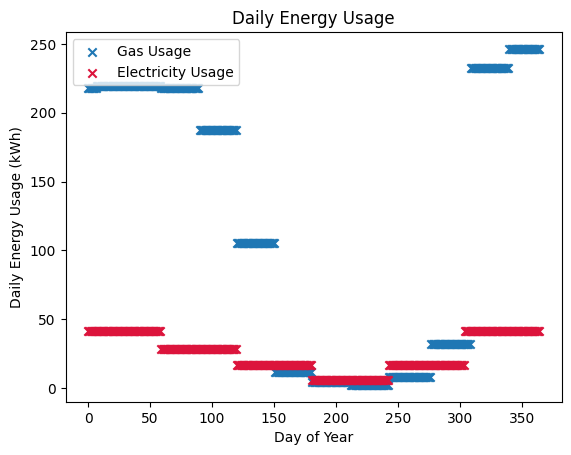

In [ ]:
plt.scatter(days,daily_gas, color = "tab:blue", marker='x',label = "Gas Usage")
plt.scatter(days,daily_elec,color = "crimson", marker='x',label = "Electricity Usage")
plt.title('Daily Energy Usage')
plt.xlabel('Day of Year')
plt.ylabel('Daily Energy Usage (kWh)')
plt.legend()
plt.show()

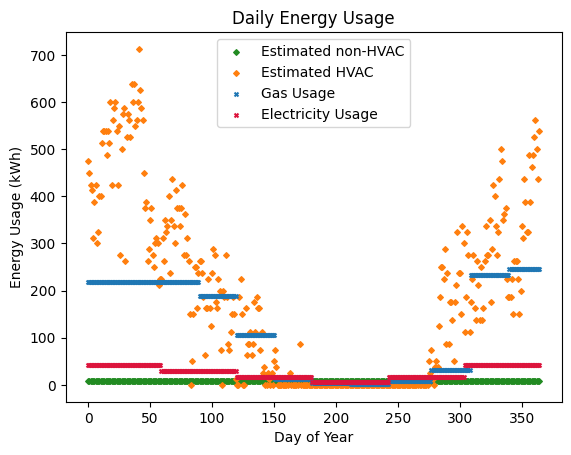

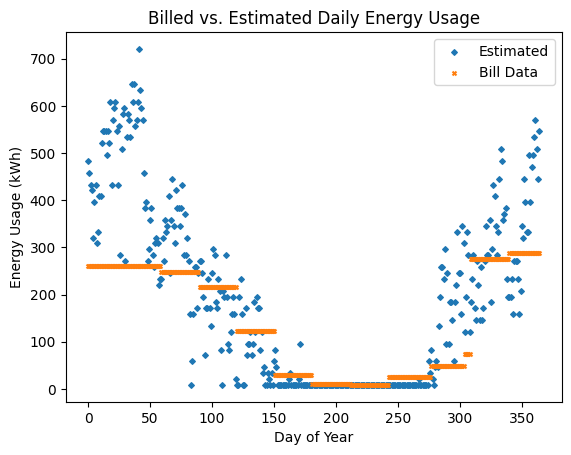

In [ ]:
# Plot functions above
plot_daily_all(UA_hp, "F", "low")
plot_daily_total(UA_hp, "F", "low")

## Define Hourly Schedule

In [ ]:
# EACH NUMBER IN THE VARIABLES BELOW SHOULD BE THE HEAT VALUE OF THE DAY
Sunday = np.hstack([np.full(8,8),np.full(10,12), np.full(6,8)])
Monday = np.hstack([np.full(8,8),np.full(10,17), np.full(6,8)])
Tuesday = np.hstack([np.full(8,8),np.full(10,17), np.full(6,8)])
Wednesday = np.hstack([np.full(8,8),np.full(10,17), np.full(6,8)])
Thursday = np.hstack([np.full(8,8),np.full(10,17), np.full(6,8)])
Friday = np.hstack([np.full(8,8),np.full(10,17), np.full(6,8)])
Saturday = np.hstack([np.full(8,8),np.full(10,12), np.full(6,8)])


Sunday_high =      np.hstack([np.full(8,8),np.full(20-7,31),np.full(3,8)])
Monday_high =      np.hstack([np.full(8,8),np.full(16-7,23),np.full(20-16,31),np.full(3,8)])
Tuesday_high =     np.hstack([np.full(8,8),np.full(16-7,23),np.full(22-16,31),8])
Wednesday_high =   np.hstack([np.full(8,8),np.full(16-7,23),np.full(20-16,31),np.full(3,8)])
Thursday_high =    np.hstack([np.full(8,8),np.full(16-7,23),np.full(20-16,31),np.full(3,8)])
Friday_high =      np.hstack([np.full(8,8),np.full(16-7,23),np.full(20-16,31),np.full(3,8)])
Saturday_high =    np.hstack([np.full(8,8),np.full(20-7,31),np.full(3,8)])

activity_coef = 2 # assume three times the daily activity in future compared to 2024

In [ ]:
print(Sunday)
print(Sunday_high)

[ 8  8  8  8  8  8  8  8 12 12 12 12 12 12 12 12 12 12  8  8  8  8  8  8]
[ 8  8  8  8  8  8  8  8 31 31 31 31 31 31 31 31 31 31 31 31 31  8  8  8]


In [ ]:
weekly_vals = np.array([Monday, Tuesday, Wednesday, Thursday, Friday, Saturday,Sunday])
weekly_vals_high = np.array([Monday_high, Tuesday_high, Wednesday_high, Thursday_high, Friday_high, Saturday_high,Sunday_high])
## Inputted a date, this outputs the heat value for the day of the week that date is.
def dayvals(date,activity): #activity = "low" or "high"

  # date should be the day of the year (between 0 and 364)
  # is date = 0, it is Monday, Jan. 1, 2024 (notice the weekly value array start on Monday)
  day = date % 7
  if type(day) != int:
    day = day.astype(int)
  if activity == "low":
    dayvals = weekly_vals[day]
  elif activity == "high":
    dayvals = weekly_vals_high[day]
  return dayvals


# Graph Hourly Data

In [ ]:
def fracheat(daily_energy_array, activity):
    frac_heat = []

    for i,day in enumerate(days):
        daily_heat_pattern = np.asarray(dayvals(day, activity))  # shape (24,)
        week_valtot = 0;
        for k in range(7):
          day_of_week = day + k
          week_valtot += np.sum(np.asarray(dayvals(day_of_week, activity)))
        if activity == "low":
          coef = 1
        else:
          coef = activity_coef
        # normalize so fractions for week equal 1; multiply by activity coefficient

        day_total = np.sum(daily_heat_pattern)
        frac_pattern = coef * daily_heat_pattern / day_total #week_valtot
        #print('daily_heat_pattern', daily_heat_pattern)
        #print('frac_pattern', frac_pattern)
        #print('week_valtot', day_total)

        # scale by daily energy
        fracheat_for_day = frac_pattern * daily_energy_array[i]
        #print('fracheat_for_day', str(i), fracheat_for_day)

        frac_heat.extend(fracheat_for_day)

    return np.array(frac_heat)


In [ ]:
def back_to_gas_elec(UA,cooling, activity):
  # Import values for daily HVAC + non-HVAC
  daily_non_HVAC, daily_HVAC = daily_energy(UA, cooling, activity)
  heating_deg_daily = np.maximum(heating_balance_point - tav, 0)
  # heat_deg = maximum of heating balance point - t_av vs. 0 (e.i. heating is on if outside temperature is cooler than balance point)
  if cooling == "T":
    cooling_deg_daily = np.maximum(tav - cooling_balance_point, 0)
    # cooling turns on if outisde temperature is warmer than balance point
  else:
    cooling_deg_daily  = 0
  total_deg = heating_deg_daily + cooling_deg_daily


  # Define constants + assumed base values
  elec_fraction = np.sum(daily_elec)/np.sum(daily_gas+daily_elec)

  elec_base = np.minimum(daily_non_HVAC + daily_HVAC) * elec_fraction
  gas_base = np.minimum(daily_non_HVAC + daily_HVAC) * (1-elec_fraction)


In [ ]:
## CURRENT USAGE; ALL THREE RETROFIT SITUATIONS -------------------
# Low activity, No retrofit
daily_non_hvac, daily_hvac = daily_energy(UA_hp, "F", "low")
hourly_non_hvac = fracheat(daily_non_hvac, "low")
hourly_hvac = fracheat(daily_hvac, "low")
hourly_elec = fracheat(daily_elec, "low")
hourly_gas = fracheat(daily_gas, "low")
hourly_total = hourly_non_hvac + hourly_hvac
daily_total = daily_non_hvac + daily_hvac

# Low Activity, Light Retrofit
daily_non_hvac_2, daily_hvac_2 = daily_energy(0.9*UA_hp, "F", "low")
hourly_non_hvac_2 = fracheat(daily_non_hvac_2, "low")
hourly_hvac_2 = fracheat(daily_hvac_2, "low")
hourly_total_2 = hourly_non_hvac_2 + hourly_hvac_2
daily_total_2 = daily_non_hvac_2 + daily_hvac_2

# Low Activity, Heavy Retrofit
daily_non_hvac_3, daily_hvac_3 = daily_energy(0.75*UA_hp, "F", "low")
hourly_non_hvac_3 = fracheat(daily_non_hvac_3, "low")
hourly_hvac_3 = fracheat(daily_hvac_3, "low")
hourly_total_3 = hourly_non_hvac_3 + hourly_hvac_3
daily_total_3 = daily_non_hvac_3 + daily_hvac_3

## HIGH/FUTURE USAGE; ALL THREE RETROFIT SITUATIONS -----------
# High Activity, No Retrofit
daily_non_hvac_4a, daily_hvac_4a = daily_energy(UA_hp, "F", "high")
hourly_non_hvac_4a = fracheat(daily_non_hvac_4a, "high")
hourly_hvac_4a = fracheat(daily_hvac_4a, "high")
hourly_total_4a = hourly_non_hvac_4a + hourly_hvac_4a
daily_total_4a = daily_non_hvac_4a + daily_hvac_4a

# High Activity, Light Retrofit
daily_non_hvac_4, daily_hvac_4 = daily_energy(0.9*UA_hp, "F", "high")
hourly_non_hvac_4 = fracheat(daily_non_hvac_4, "high")
hourly_hvac_4 = fracheat(daily_hvac_4, "high")
hourly_total_4 = hourly_non_hvac_4 + hourly_hvac_4
daily_total_4 = daily_non_hvac_4 + daily_hvac_4

# High Activity, Heavy Retrofit
daily_non_hvac_5, daily_hvac_5 = daily_energy(0.75*UA_hp, "F", "high")
hourly_non_hvac_5 = fracheat(daily_non_hvac_5, "high")
hourly_hvac_5 = fracheat(daily_hvac_5, "high")
hourly_total_5 = hourly_non_hvac_5 + hourly_hvac_5
daily_total_5 = daily_non_hvac_5 + daily_hvac_5


In [ ]:
# Low activity, No retrofit
# Export Data to Hourly_Data.csv (saves to shared capstone folder)
ds = pd.DataFrame([hourly_non_hvac+hourly_hvac]).T
ds.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)
dsa = pd.DataFrame([hourly_hvac* 0.1036 / 30.36]).T
dsa.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Current Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)
dsb = pd.DataFrame([hourly_non_hvac]).T
dsb.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Current Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)

# Low Activity, Light Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds2 = pd.DataFrame([hourly_non_hvac_2+hourly_hvac_2]).T
ds2.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)
ds2 = pd.DataFrame([hourly_hvac_2* 0.1036 / 30.36]).T
ds2.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Light Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)
ds2 = pd.DataFrame([hourly_non_hvac_2]).T
ds2.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Light Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)

# Low Activity, Heavy Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds3 = pd.DataFrame([hourly_non_hvac_3+hourly_hvac_3]).T
ds3.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)
ds3a = pd.DataFrame([hourly_hvac_3* 0.1036 / 30.36]).T
ds3a.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Heavy Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)
ds3b = pd.DataFrame([hourly_non_hvac_3]).T
ds3b.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Heavy Retrofit, Low Activity Hourly Data (Check).csv', index=False, header = False)

# High Activity, No Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds4a = pd.DataFrame([hourly_non_hvac_4a+hourly_hvac_4a]).T
ds4a.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)
ds4A = pd.DataFrame([hourly_hvac_4a* 0.1036 / 30.36]).T
ds4A.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Current Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)
ds4B = pd.DataFrame([hourly_non_hvac_4a]).T
ds4B.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Current Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)

# High Activity, Light Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds4 = pd.DataFrame([hourly_non_hvac_4+hourly_hvac_4]).T
ds4.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)
ds4b = pd.DataFrame([hourly_hvac_4* 0.1036 / 30.36]).T
ds4b.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Light Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)
ds4c = pd.DataFrame([hourly_non_hvac_4]).T
ds4c.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Light Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)

# High Activity, Heavy Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds5 = pd.DataFrame([hourly_non_hvac_5+hourly_hvac_5]).T
ds5.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)
ds5a = pd.DataFrame([hourly_hvac_5* 0.1036 / 30.36]).T
ds5a.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Heavy Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)
ds5b = pd.DataFrame([hourly_non_hvac_5]).T
ds5b.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Heavy Retrofit, High Activity Hourly Data (Check).csv', index=False, header = False)


In [ ]:
'''
# assume hvac = gas and non-hvac = elec

# Gas profile

# Low activity, No retrofit
# Export Data to Hourly_Data.csv (saves to shared capstone folder)
dsgas = pd.DataFrame([hourly_hvac * 0.1036 / 30.36]).T
dsgas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current-Low Activity Gas (Check).csv', index=False, header = False)

# Low Activity, Light Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds2gas = pd.DataFrame([hourly_hvac_2 * 0.1036 / 30.36]).T
ds2gas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light-Low Gas MMBtu (Check).csv', index=False, header = False)

# Low Activity, Heavy Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds3gas = pd.DataFrame([hourly_hvac_3 * 0.1036 / 30.36]).T
ds3gas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy-Low Gas MMBtu (Check).csv', index=False, header = False)

# High Activity, No Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds4agas = pd.DataFrame([hourly_hvac_4a * 0.1036 / 30.36]).T
ds4agas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current-High Gas MMBtu (Check).csv', index=False, header = False)

# High Activity, Light Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds4gas = pd.DataFrame([hourly_hvac_4 * 0.1036 / 30.36]).T
ds4gas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light-High Gas MMBtu (Check).csv', index=False, header = False)

# High Activity, Heavy Retrofit
# Export Data to Hourly_Data.csv (click folder icon on left)
ds5gas = pd.DataFrame([hourly_hvac_5 * 0.1036 / 30.36]).T
ds5gas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy-High Gas MMBtu (Check).csv', index=False, header = False)
'''

"\n# assume hvac = gas and non-hvac = elec\n\n# Gas profile\n\n# Low activity, No retrofit\n# Export Data to Hourly_Data.csv (saves to shared capstone folder)\ndsgas = pd.DataFrame([hourly_hvac * 0.1036 / 30.36]).T\ndsgas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current-Low Activity Gas (Check).csv', index=False, header = False)\n\n# Low Activity, Light Retrofit\n# Export Data to Hourly_Data.csv (click folder icon on left)\nds2gas = pd.DataFrame([hourly_hvac_2 * 0.1036 / 30.36]).T\nds2gas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light-Low Gas MMBtu (Check).csv', index=False, header = False)\n\n# Low Activity, Heavy Retrofit\n# Export Data to Hourly_Data.csv (click folder icon on left)\nds3gas = pd.DataFrame([hourly_hvac_3 * 0.1036 / 30.36]).T\nds3gas.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy-Low Gas MMBtu (Check).csv', index=False, header = False)\n\n# High Activity, No Retrofit\n# Export Data to Hourly_Data.csv (click folder icon on left)

In [ ]:
# no heat pump data
data = [[max(hourly_total), min(hourly_total), np.mean(hourly_total), sum(hourly_total),
         sum(hourly_total)/sum(daily_total), sum(daily_hvac)],
 [max(hourly_total_4a), min(hourly_total_4a), np.mean(hourly_total_4a), sum(hourly_total_4a),
  sum(hourly_total_4a)/sum(daily_total_4a), sum(hourly_hvac_4a)],
  [max(hourly_total_2), min(hourly_total_2), np.mean(hourly_total_2), sum(hourly_total_2),
   sum(hourly_total_2)/sum(daily_total_2), sum(hourly_hvac_2)],
   [max(hourly_total_4), min(hourly_total_4), np.mean(hourly_total_4), sum(hourly_total_4),
    sum(hourly_total_4)/sum(daily_total_4), sum(hourly_hvac_4)],
    [max(hourly_total_3), min(hourly_total_3), np.mean(hourly_total_3), sum(hourly_total_3),
     sum(hourly_total_3)/sum(daily_total_3), sum(hourly_hvac_3)],
     [max(hourly_total_5), min(hourly_total_5), np.mean(hourly_total_5), sum(hourly_total_5),
      sum(hourly_total_5)/sum(daily_total_5), sum(hourly_hvac_5)]]
df = pd.DataFrame(
    data,
    index=['Current-Low', 'Current-High', 'Light-Low', 'Light-High', 'Heavy-Low', 'Heavy-High'],
    columns=['Max Load (kW)', 'Min Load (kW)', 'Avg Load (kW)', 'Total', 'ratio to daily', 'Total HVAC']
)

print(df)

              Max Load (kW)  Min Load (kW)  Avg Load (kW)         Total  \
Current-Low       38.930664       0.235206       7.961041   69738.71792   
Current-High      96.785406       0.540351      16.612999  145529.87168   
Light-Low         35.087578       0.235206       7.199483   63067.46792   
Light-High        87.352231       0.540351      15.089883  132187.37168   
Heavy-Low         29.322951       0.235206       6.057145   53060.59292   
Heavy-High        73.202470       0.540351      12.805208  112173.62168   

              ratio to daily  Total HVAC  
Current-Low              1.0   66712.500  
Current-High             2.0  133425.000  
Light-Low                1.0   60041.250  
Light-High               2.0  120082.500  
Heavy-Low                1.0   50034.375  
Heavy-High               2.0  100068.750  


In [ ]:
# gas and elec data assuming hvac = gas
datagaselec = [[max(hourly_hvac * 0.1036 / 30.36), min(hourly_hvac * 0.1036 / 30.36), np.mean(hourly_hvac * 0.1036 / 30.36), sum(hourly_hvac * 0.1036 / 30.36),
         np.mean(hourly_non_hvac)],
 [max(hourly_hvac_4a * 0.1036 / 30.36), min(hourly_hvac_4a * 0.1036 / 30.36), np.mean(hourly_hvac_4a * 0.1036 / 30.36), sum(hourly_hvac_4a * 0.1036 / 30.36),
  np.mean(hourly_non_hvac_4a)],
  [max(hourly_hvac_2 * 0.1036 / 30.36), min(hourly_hvac_2 * 0.1036 / 30.36), np.mean(hourly_hvac_2 * 0.1036 / 30.36), sum(hourly_hvac_2 * 0.1036 / 30.36),
   np.mean(hourly_non_hvac_2)],
   [max(hourly_hvac_4 * 0.1036 / 30.36), min(hourly_hvac_4 * 0.1036 / 30.36), np.mean(hourly_hvac_4 * 0.1036 / 30.36), sum(hourly_hvac_4 * 0.1036 / 30.36),
    np.mean(hourly_non_hvac_4)],
    [max(hourly_hvac_3 * 0.1036 / 30.36), min(hourly_hvac_3 * 0.1036 / 30.36), np.mean(hourly_hvac_3 * 0.1036 / 30.36), sum(hourly_hvac_3 * 0.1036 / 30.36),
     np.mean(hourly_non_hvac_3)],
     [max(hourly_hvac_5 * 0.1036 / 30.36), min(hourly_hvac_5 * 0.1036 / 30.36), np.mean(hourly_hvac_5 * 0.1036 / 30.36), sum(hourly_hvac_5 * 0.1036 / 30.36),
      np.mean(hourly_non_hvac_5)]]
dfgaselec = pd.DataFrame(
    datagaselec,
    index=['Current-Low', 'Current-High', 'Light-Low', 'Light-High', 'Heavy-Low', 'Heavy-High'],
    columns=['Max Load (MMBtu)', 'Min Load (MMBtu)', 'Avg Load (MMBtu)', 'Total (MMBtu)', 'non HVAC (kWh)']
)

print(dfgaselec)

              Max Load (MMBtu)  Min Load (MMBtu)  Avg Load (MMBtu)  \
Current-Low           0.131141               0.0          0.025987   
Current-High          0.321896               0.0          0.051975   
Light-Low             0.118027               0.0          0.023389   
Light-High            0.289707               0.0          0.046777   
Heavy-Low             0.098356               0.0          0.019490   
Heavy-High            0.241422               0.0          0.038981   

              Total (MMBtu)  non HVAC (kWh)  
Current-Low      227.648715        0.345459  
Current-High     455.297431        1.381835  
Light-Low        204.883844        0.345459  
Light-High       409.767688        1.381835  
Heavy-Low        170.736537        0.345459  
Heavy-High       341.473073        1.381835  


69738.71791999834
145529.87167999486


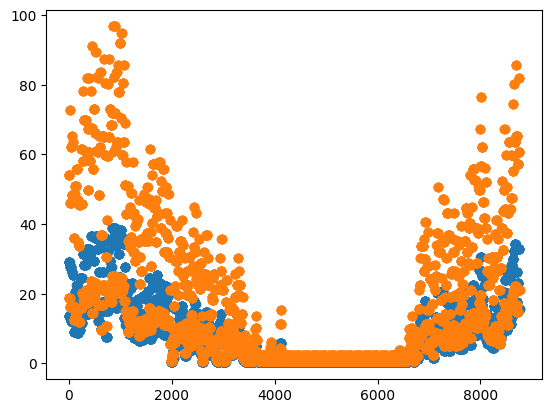

In [ ]:
plt.scatter(hours, hourly_non_hvac+hourly_hvac, label='low activity')
plt.scatter(hours,hourly_non_hvac_4a+hourly_hvac_4a, label='high activity')
#print(len(hours))
#print(len(hourly_non_hvac+hourly_hvac))
print(sum(hourly_non_hvac+hourly_hvac))
print(sum(hourly_non_hvac_4a+hourly_hvac_4a))

Text(0, 0.5, 'Energy [kWh]')

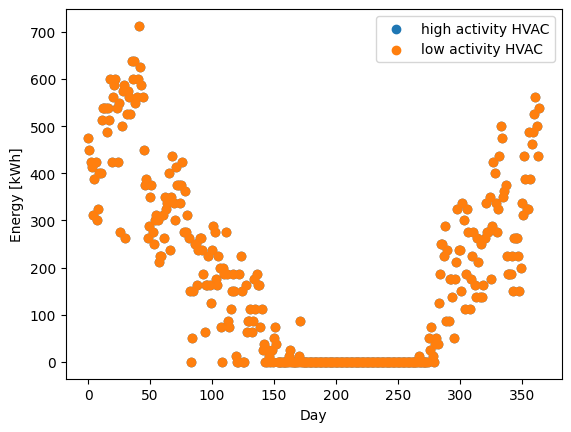

In [ ]:
#plt.scatter(days, daily_non_hvac_4a+daily_hvac_4a, label='high activity')
#plt.scatter(days, daily_non_hvac+daily_hvac, label='low activity')

plt.scatter(days, daily_hvac_4a, label='high activity HVAC')
plt.scatter(days, daily_hvac, label='low activity HVAC')

#plt.scatter(days, daily_non_hvac_4a, label='high activity non-HVAC')
#plt.scatter(days, daily_non_hvac, label='low activity non-HVAC')
plt.legend()
plt.xlabel('Day')
plt.ylabel('Energy [kWh]')

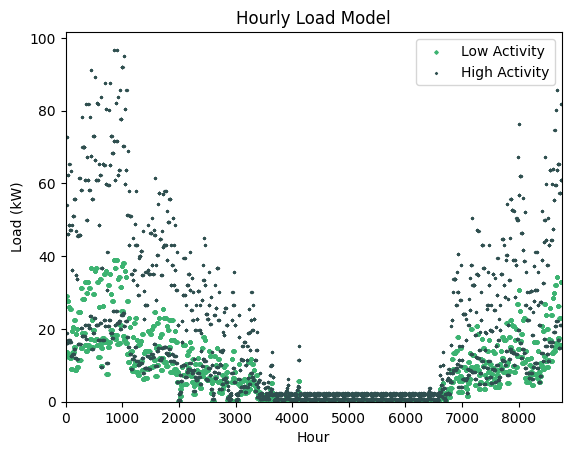

In [ ]:
plt.figure()
plt.scatter(hours,hourly_non_hvac+hourly_hvac, color = 'mediumseagreen', marker = 'D', s = 3, label = 'Low Activity')

plt.scatter(hours,hourly_non_hvac_4a+hourly_hvac_4a,color = 'darkslategray', marker = 'D', s = 1, label = 'High Activity')
plt.title("Hourly Load Model")
plt.xlabel("Hour")
plt.ylabel("Load (kW)")
plt.xlim(0,8760)
plt.ylim(0,None)
plt.legend()
plt.show()

In [ ]:
np.sum(daily_hvac+daily_non_hvac)/np.sum(daily_gas+daily_elec)

np.float64(1.3151418293322603)

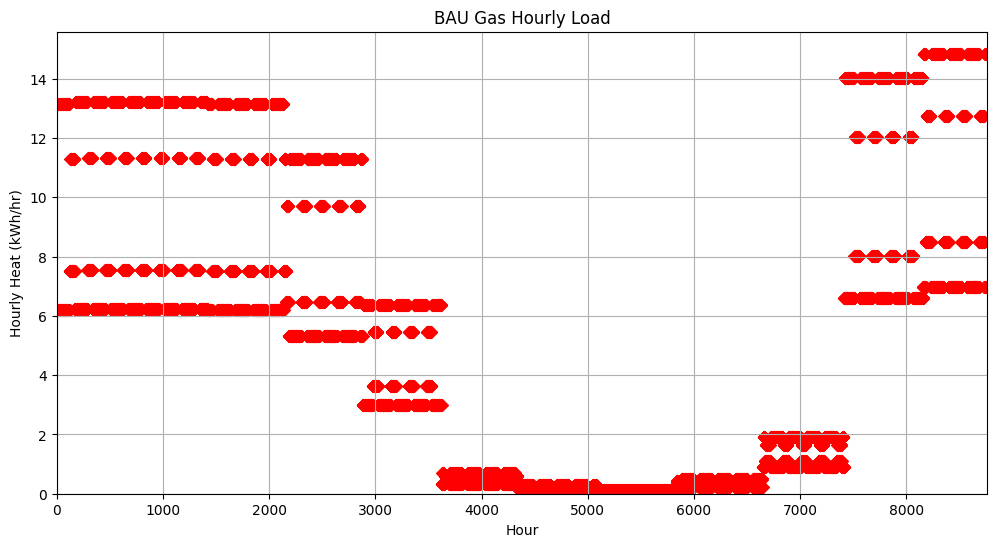

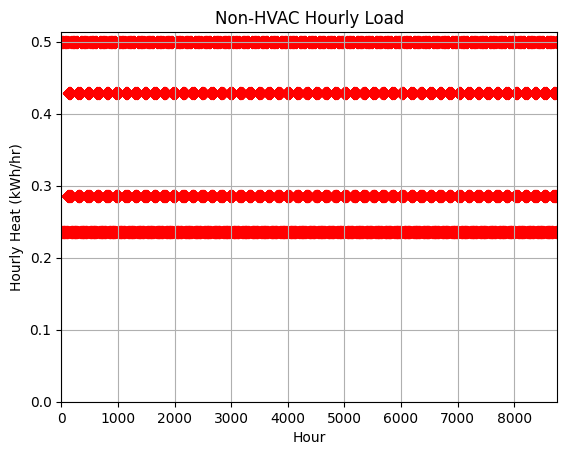

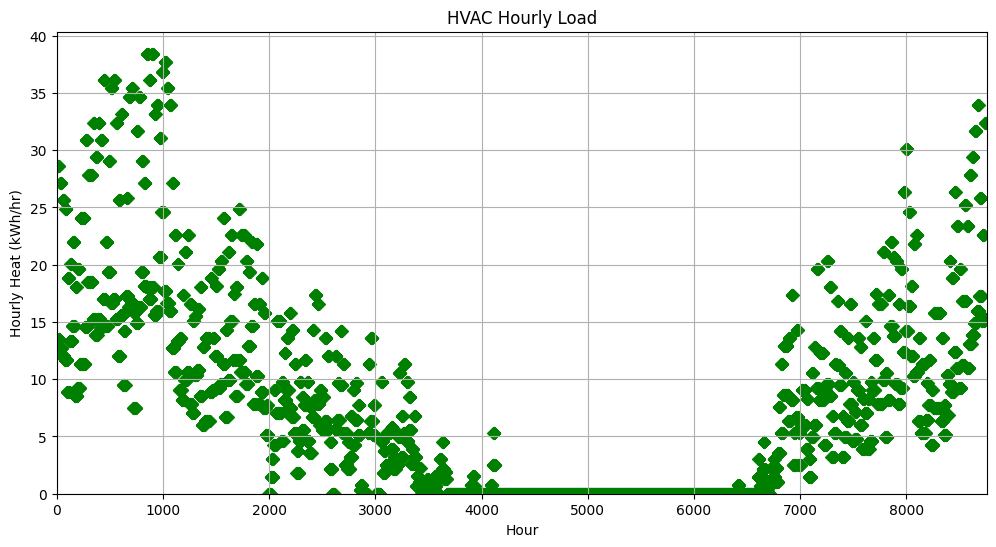

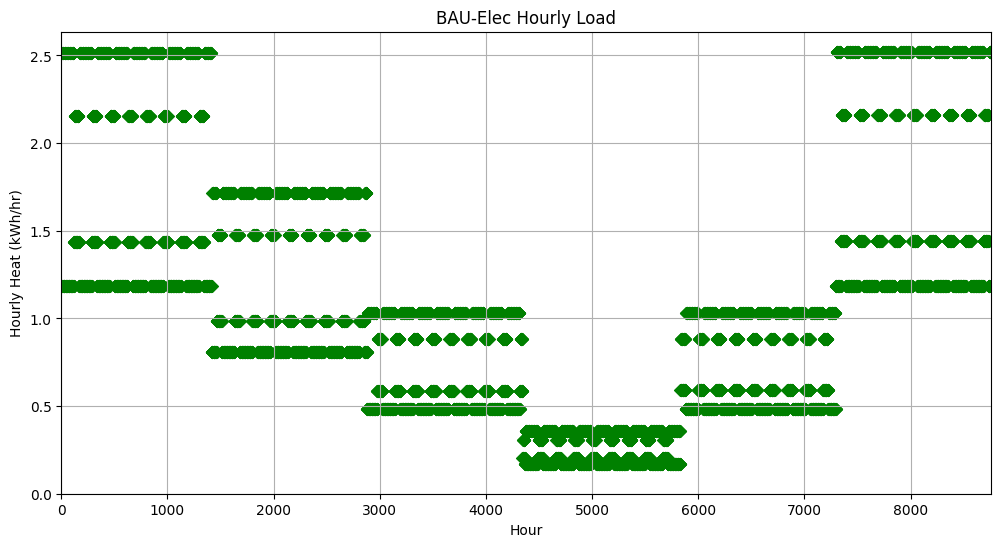

<Figure size 1200x600 with 0 Axes>

In [ ]:
def plot_hourly(hourly_non_hvac, hourly_hvac):
  hourly_gas = fracheat(daily_gas, "low")
  hourly_elec = fracheat(daily_elec, "low")

  plt.figure(figsize=(12, 6))
  plt.scatter(hours,hourly_gas, color = 'red', marker = 'D')
  plt.title("BAU Gas Hourly Load")
  plt.xlabel("Hour")
  plt.ylabel("Hourly Heat (kWh/hr)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.grid(True)
  plt.show()

  plt.scatter(hours,hourly_non_hvac, color = 'red', marker = 'D')
  plt.title("Non-HVAC Hourly Load")
  plt.xlabel("Hour")
  plt.ylabel("Hourly Heat (kWh/hr)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(12, 6))
  plt.scatter(hours,hourly_hvac, color = 'green', marker='D')
  plt.title("HVAC Hourly Load")
  plt.xlabel("Hour")
  plt.ylabel("Hourly Heat (kWh/hr)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(12, 6))
  plt.scatter(hours,hourly_elec, color = 'green', marker='D')
  plt.title("BAU-Elec Hourly Load")
  plt.xlabel("Hour")
  plt.ylabel("Hourly Heat (kWh/hr)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(12, 6))
  daily_non_hvac, daily_hvac = daily_energy(UA_hp, "F", "low")
  hourly_non_hvac = fracheat(daily_non_hvac, "low")
  hourly_hvac = fracheat(daily_hvac, "low")
  hourly_elec = fracheat(daily_elec, "low")
  hourly_gas = fracheat(daily_gas, "low")

plot_hourly(hourly_non_hvac, hourly_hvac)

In [ ]:
# Define constants


# energy_model calculates the value for all four energy types for each day
# and outputs an array for each
def COP(days):
  COP = np.zeros(len(days)*24)
  idx = 0
  for day in days:
    day = int(day)
    t = tav[day]
    COP[idx:idx+24] = 0.0351*t + 1.68
    idx += 24

  for h in hours:
    h = int(h)
    if COP[h] != COP[h]:
      print(h)

  return COP

def heat_pump_model(UA, activity):
    # Calculate heating and cooling degrees for each day
    heating_deg_daily = np.maximum(heating_balance_point - tav, 0)
    cooling_deg_daily = np.maximum(tav - cooling_balance_point, 0)

    total_deg = np.sum(heating_deg_daily) + np.sum(cooling_deg_daily)

    daily_non_HVAC,daily_HVAC = daily_energy(UA, "T", activity) # Recalculate HVAC with cooling
    HVAC = fracheat(daily_HVAC, activity)
    non_HVAC = fracheat(daily_non_HVAC, activity)
    '''
    COP_hourly = COP(days)
    total_hp_only = HVAC / COP_hourly / gaseff
    total_hp = non_HVAC / COP_hourly / eleceff + total_hp_only
    print(sum(total_hp_only))
    print(sum(total_hp))
    '''
    elec = fracheat(daily_elec, activity)
    gas = fracheat(daily_gas, activity)

    elec_fraction = np.sum(elec)/np.sum(gas+elec)


    COP_hourly = COP(days)
    elec_to_hp = HVAC  * 1/COP_hourly  * elec_fraction #/eleceff
    gas_to_hp = HVAC  * 1/COP_hourly * (1-elec_fraction) #/gaseff

    total_hp_only = gas_to_hp + elec_to_hp # total HVAC energy demand from heat pump
    total_hp = total_hp_only + non_HVAC    # total energy demand

    print(elec_fraction)
    if UA == UA_hp:
      retrofit = "No Retrofit,"
    elif UA == 0.75*UA_hp:
      retrofit = "Heavy Retrofit,"
    else:
      retrofit = "Light Retrofit,"
    '''
    #plt.scatter(hours,HVAC+, color = 'green', marker='D', label = "HVAC")
    #plt.scatter(hours,non_HVAC, color = 'red', marker = 'D',label = "non-HVAC")
    plt.scatter(hours,total_hp,  marker='X',  s=2,label = f"{retrofit} {activity} activity")
    plt.title("Heat Pump Hourly Energy Consumption")
    plt.xlabel("Hour")
    plt.ylabel("Energy (kWh)")
    plt.xlim(0,8760)
    plt.ylim(0,None)
    plt.grid(True)
    plt.legend()
    '''

    return total_hp_only, total_hp

In [ ]:
# HEAT PUMP
plt.figure(figsize=(12, 6))
dhp = pd.DataFrame([heat_pump_model(UA_hp,"low"),heat_pump_model(UA_hp,"high"),
                   heat_pump_model(0.9*UA_hp,"low"),heat_pump_model(0.9*UA_hp,"high"),
                   heat_pump_model(0.75*UA_hp,"low"),heat_pump_model(0.75*UA_hp,"high")]).T
#dhp.columns = ['Low Activity, Current Retrofit Heat Pump','High Activity, Current Retrofit Heat Pump',
#'Low Activity, Light Retrofit Heat Pump','High Activity, Light Retrofit Heat Pump',
#'Low Activity, Heavy Retrofit Heat Pump','High Activity, Heavy Retrofit Heat Pump']

#dhp.to_csv('/content/drive/MyDrive/Capstone/Heat Pump for all six.csv', index=False)

0.17348977304742608
0.17348977304742608
0.17348977304742608
0.17348977304742608
0.17348977304742608
0.17348977304742608


<Figure size 1200x600 with 0 Axes>

In [ ]:

# current, low
total_hp_only1, total_hp1 = heat_pump_model(UA_hp,"low")
gashp1 = pd.DataFrame([total_hp_only1 * 0.1036 / 30.36]).T
elecp1 = pd.DataFrame([total_hp1-total_hp_only1]).T

# current, high
total_hp_only2, total_hp2 = heat_pump_model(UA_hp,"high")
gashp2 = pd.DataFrame([total_hp_only2 * 0.1036 / 30.36]).T
elecp2 = pd.DataFrame([total_hp2-total_hp_only2]).T

# light, low
total_hp_only3, total_hp3 = heat_pump_model(0.9*UA_hp,"low")
gashp3 = pd.DataFrame([total_hp_only3 * 0.1036 / 30.36]).T
elecp3 = pd.DataFrame([total_hp3-total_hp_only3]).T

# light, high
total_hp_only4, total_hp4 = heat_pump_model(0.9*UA_hp,"high")
gashp4 = pd.DataFrame([total_hp_only4 * 0.1036 / 30.36]).T
elecp4 = pd.DataFrame([total_hp4-total_hp_only4]).T

# heavy, low
total_hp_only5, total_hp5 = heat_pump_model(0.75*UA_hp,"low")
gashp5 = pd.DataFrame([total_hp_only5 * 0.1036 / 30.36]).T
elecp5 = pd.DataFrame([total_hp5-total_hp_only5]).T

# heavy, high
total_hp_only6, total_hp6 = heat_pump_model(0.75*UA_hp,"high")
gashp6 = pd.DataFrame([total_hp_only6 * 0.1036 / 30.36]).T
elecp6 = pd.DataFrame([total_hp6-total_hp_only6]).T


0.17348977304742608
0.17348977304742608
0.17348977304742608
0.17348977304742608
0.17348977304742608
0.17348977304742608


In [ ]:
gashp1.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Current Low HP.csv', index=False, header = False)
gashp2.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Current High HP.csv', index=False, header = False)
gashp3.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Light Low HP.csv', index=False, header = False)
gashp4.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Light High HP.csv', index=False, header = False)
gashp5.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Heavy Low HP.csv', index=False, header = False)
gashp6.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Gas Heavy High HP.csv', index=False, header = False)

elecp1.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Current Low HP.csv', index=False, header = False)
elecp2.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Current High HP.csv', index=False, header = False)
elecp3.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Light Low HP.csv', index=False, header = False)
elecp4.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Light High HP.csv', index=False, header = False)
elecp5.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Heavy Low HP.csv', index=False, header = False)
elecp6.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Elec Heavy High HP.csv', index=False, header = False)

In [ ]:
# current, low
dhp1 = pd.DataFrame([total_hp1]).T
dhp1.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current Retrofit, Low Activity Heat Pump Hourly (Check).csv', index=False, header = False)

# current, high
dhp2 = pd.DataFrame([total_hp2]).T
dhp2.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Current Retrofit, High Activity Heat Pump Hourly (Check).csv', index=False, header = False)

# light, low
dhp3 = pd.DataFrame([total_hp3]).T
dhp3.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light Retrofit, Low Activity Heat Pump Hourly (Check).csv', index=False, header = False)

# light, high
dhp4 = pd.DataFrame([total_hp4]).T
dhp4.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Light Retrofit, High Activity Heat Pump Hourly (Check).csv', index=False, header = False)

# heavy, low
dhp5 = pd.DataFrame([total_hp5]).T
dhp5.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy Retrofit, Low Activity Heat Pump Hourly (Check).csv', index=False, header = False)

# heavy, high
dhp6 = pd.DataFrame([total_hp6]).T
dhp6.to_csv('/content/drive/MyDrive/Capstone_Spring_Team2+3/Heavy Retrofit, High Activity Heat Pump Hourly (Check).csv', index=False, header = False)

In [ ]:
# Hourly with HP
data_hp = [[max(total_hp1), min(total_hp1), np.mean(total_hp1), sum(total_hp1), sum(total_hp_only1), sum(total_hp_only1)*0.1465, sum(total_hp_only1)/sum(total_hp1)],
 [max(total_hp2), min(total_hp2), np.mean(total_hp2), sum(total_hp2), sum(total_hp_only2), sum(total_hp_only2)*0.1465, sum(total_hp_only2)/sum(total_hp2)],
  [max(total_hp3), min(total_hp3), np.mean(total_hp3), sum(total_hp3), sum(total_hp_only3), sum(total_hp_only3)*0.1465, sum(total_hp_only3)/sum(total_hp3)],
   [max(total_hp4), min(total_hp4), np.mean(total_hp4), sum(total_hp4), sum(total_hp_only4), sum(total_hp_only4)*0.1465, sum(total_hp_only4)/sum(total_hp4)],
    [max(total_hp5), min(total_hp5), np.mean(total_hp5), sum(total_hp5), sum(total_hp_only5), sum(total_hp_only5)*0.1465, sum(total_hp_only5)/sum(total_hp5)],
     [max(total_hp6), min(total_hp6), np.mean(total_hp6), sum(total_hp6), sum(total_hp_only6), sum(total_hp_only6)*0.1465, sum(total_hp_only6)/sum(total_hp6)]]
dfhp = pd.DataFrame(
    data_hp,
    index=['Current-Low', 'Current-High', 'Light-Low', 'Light-High', 'Heavy-Low', 'Heavy-High'],
    columns=['Max Load (kW)', 'Min Load (kW)', 'Avg Load (kW)', 'Total', 'Total HVAC', 'cost', 'frac hvac']
)

print(dfhp)

              Max Load (kW)  Min Load (kW)  Avg Load (kW)         Total  \
Current-Low       13.793315       0.235206       2.756768  24149.283616   
Current-High      35.083679       0.540351       6.204452  54351.003072   
Light-Low         12.463965       0.235206       2.515637  22036.977047   
Light-High        31.820677       0.540351       5.722191  50126.389933   
Heavy-Low         10.469939       0.235206       2.153940  18868.517192   
Heavy-High        26.926175       0.540351       4.998798  43789.470224   

                Total HVAC         cost  frac hvac  
Current-Low   21123.065696  3094.529124   0.874687  
Current-High  42246.131392  6189.058249   0.777283  
Light-Low     19010.759127  2785.076212   0.862675  
Light-High    38021.518253  5570.152424   0.758513  
Heavy-Low     15842.299272  2320.896843   0.839615  
Heavy-High    31684.598544  4641.793687   0.723567  


In [ ]:
discount_inflation = 0.025 #%
NG_escalation = 0.05 #%
elec_escalation = 0.05 #%
BAU_Y1 = 0 #$
NEW_Y1 = 0 #$

hvac_tot = [sum(daily_hvac),
    sum(hourly_hvac_4a),
    sum(hourly_hvac_2),
    sum(hourly_hvac_4),
    sum(hourly_hvac_3),
    sum(hourly_hvac_5)]

hp_only_tot = [sum(total_hp_only1),sum(total_hp_only2),sum(total_hp_only3),
               sum(total_hp_only4),sum(total_hp_only5),sum(total_hp_only6)]

npv_1 = []
npv_10 = []
for i in range(len(hvac_tot)):
    NG_cost_Y1 = hvac_tot[i] / 30.36 * 1.5   # Cost NG Y1 ($)
    HP_cost_Y1 = hvac_tot[i] * gaseff / 3.5 * 0.1465   # Cost HP Y1 ($)
    BAU = [0]
    new = [0]

    net_cash = np.zeros(11)# []
    NPV = np.zeros(11) #[] #np.zeros(11)

    for j in range(11):
      net_cash[j] = BAU[j] - new[j]
      NPV[j] = NPV[j-1] + (net_cash[j]-net_cash[j-1]) / (1+discount_inflation)**j
      BAU.append(BAU[j] + NG_cost_Y1*(1+NG_escalation)**j)
      new.append(new[j] + HP_cost_Y1*(1+elec_escalation)**j)

    npv_1.append(round(NPV[1],2))
    npv_10.append(round(NPV[10],2))

In [ ]:
# NPV of just HP

data2 = [[x, x / 30.36, round(x / 30.36 * 1.5, 2), x * gaseff / 3.5 * 0.1465] for x in
hvac_tot] #x * gaseff / 3.5 * 0.1465

df2 = pd.DataFrame(
    data2,
    index=['Current-Low', 'Current-High', 'Light-Low', 'Light-High', 'Heavy-Low', 'Heavy-High'],
    columns=['HVAC (kWh)', 'NG (CCF)', 'Cost NG Y1 ($)', 'Cost HP Y1 ($)']
)

#df2['Cost HP Y1 ($)'] = hp_only_tot
df2['10 yr NPV ($)'] = npv_10
df2['1st yr savings ($)'] = npv_1

print(df2)

              HVAC (kWh)     NG (CCF)  Cost NG Y1 ($)  Cost HP Y1 ($)  \
Current-Low    66712.500  2197.381423         3296.07     2233.915714   
Current-High  133425.000  4394.762846         6592.14     4467.831429   
Light-Low      60041.250  1977.643281         2966.46     2010.524143   
Light-High    120082.500  3955.286561         5932.93     4021.048286   
Heavy-Low      50034.375  1648.036067         2472.05     1675.436786   
Heavy-High    100068.750  3296.072134         4944.11     3350.873571   

              10 yr NPV ($)  1st yr savings ($)  
Current-Low        11577.07             1036.25  
Current-High       23154.15             2072.50  
Light-Low          10419.37              932.63  
Light-High         20838.73             1865.25  
Heavy-Low           8682.81              777.19  
Heavy-High         17365.61             1554.38  


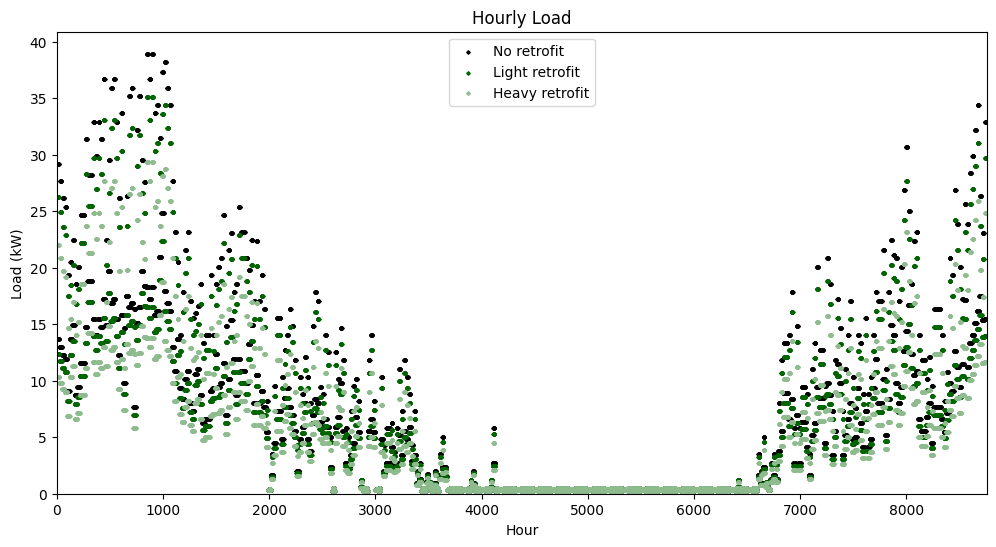

(0.0, 0.5130428709219857)

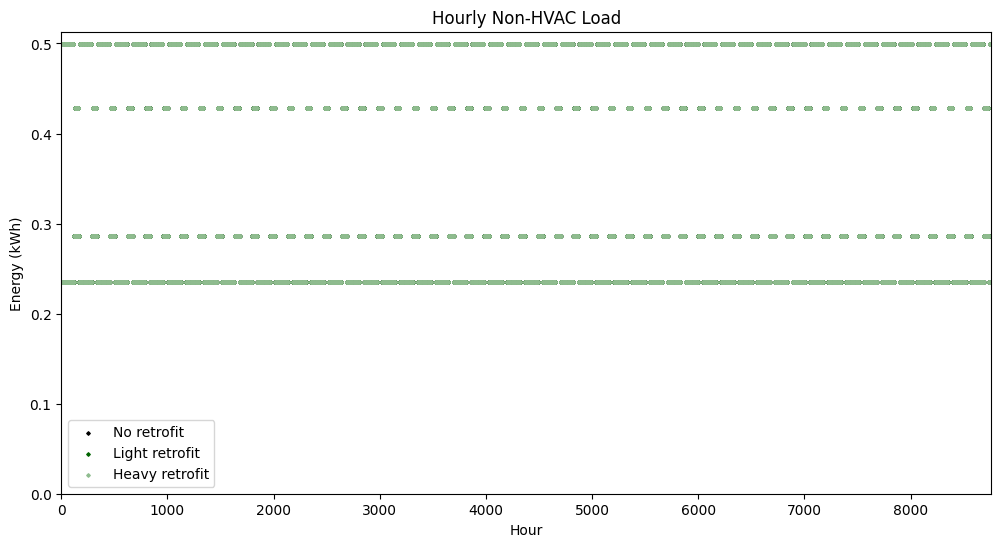

In [ ]:
plt.figure(figsize=(12, 6))
plt.scatter(hours,hourly_hvac+hourly_non_hvac, color = 'black', marker='D',s= 3, label = "No retrofit")
plt.scatter(hours,hourly_hvac_2+hourly_non_hvac_2, color = 'darkgreen', marker='D',s= 3, label = "Light retrofit")
plt.scatter(hours,hourly_hvac_3+hourly_non_hvac_3, color = 'darkseagreen', marker='D', s= 3, label = "Heavy retrofit")
plt.legend()
plt.title("Hourly Load")
plt.xlabel("Hour")
plt.ylabel("Load (kW)")
plt.xlim(0,8760)
plt.ylim(0,None)
plt.show()

plt.figure(figsize=(12, 6))
plt.scatter(hours,hourly_non_hvac, color = 'black', marker='D',s= 3, label = "No retrofit")
plt.scatter(hours,hourly_non_hvac_2, color = 'darkgreen', marker='D',s= 3, label = "Light retrofit")
plt.scatter(hours,hourly_non_hvac_3, color = 'darkseagreen', marker='D', s= 3, label = "Heavy retrofit")
plt.legend()
plt.title("Hourly Non-HVAC Load")
plt.xlabel("Hour")
plt.ylabel("Energy (kWh)")
plt.xlim(0,8760)
plt.ylim(0,None)

# Adding Billing Structures
This was discontinued, so may be inaccurate after recent changes.
###I.    Current
1.   Convert hourly electricity and gas usage to cost
2.   Plot hourly total energy cost.

### II.  Future

1.   Define program that given hour, calculates the cost of electricity.
2.   Repeat section I.


In [ ]:
# CURRENT ------------
## NUMBER ONE: CONVERT HOURLY TO COST
def current_hourly_cost(UA,activity):
  # ASSUME NO COOLING IF NO HEAT PUMP
  # ASSUME COOLING FOR HEAT PUMP
  elec = fracheat(daily_elec, activity)
  gas = fracheat(daily_gas, activity)

  elec_fraction = np.sum(elec)/np.sum(gas+elec)

  cost_per_kWh_elec = 0.1338
  cost_per_kWh_gas = .1
  cost_per_kWh = (elec_fraction*(1/eleceff) *cost_per_kWh_elec + (1-elec_fraction)*(1/gaseff)*cost_per_kWh_gas)
  base_cost = 0.3945/24

  daily_non_hvac, daily_hvac = daily_energy(UA, "F")
  hourly_non_hvac =  fracheat(daily_non_hvac, activity)
  hourly_hvac =  fracheat(daily_hvac, activity)
  total_energy = hourly_hvac + hourly_non_hvac



  cost_without_hp = total_energy * cost_per_kWh + base_cost
  hourly_non_hvac_cost = hourly_non_hvac * cost_per_kWh

  hourly_heat_pump_cost = cost_per_kWh_elec * heat_pump_model(UA,activity)
  cost_with_hp = hourly_heat_pump_cost + hourly_non_hvac_cost

  return cost_without_hp, cost_with_hp

def future_cost_per_kWh(hours):
  cost = []
  for hour in hours:
    time = hour % 24
    if time in range(0,6): # off-peak
      cost.extend([0.1309])
    elif time in range(6,17) or time in range(21,24): # mid-peak
     cost.extend([0.1409])
    else: #peak
     cost.extend([0.1610])
  return cost

def future_hourly_cost(UA,activity):
  base_cost = 0.3945/24
  cost_elec = future_cost_per_kWh(hours)
  cost_gas = future_cost_per_kWh(hours)
  daily_non_hvac, daily_hvac = daily_energy(UA, "F")
  hourly_non_hvac_cost = future_cost_per_kWh(hours) * fracheat(daily_non_hvac, activity)
  hourly_hvac_cost = future_cost_per_kWh(hours) * fracheat(daily_hvac, activity)

  cost_without_hp = hourly_non_hvac_cost + hourly_hvac_cost + base_cost

  hourly_heat_pump_cost = future_cost_per_kWh(hours) * heat_pump_model(UA,activity)
  cost_with_hp = hourly_heat_pump_cost + hourly_non_hvac_cost + base_cost

  return cost_without_hp, cost_with_hp

In [ ]:
len(future_cost_per_kWh(hours))

8760

In [ ]:
def test():
  nohp,hp = current_hourly_cost(UA_hp, "low")
  futurenohp,futurehp = future_hourly_cost(UA_hp, "low")
  plt.figure(figsize=(12, 8))
  plt.scatter(hours,nohp, color = 'cornflowerblue', marker = 'X',s = 2,label = "no HP")
  plt.scatter(hours,hp, color = 'midnightblue', marker='X',s = 2,label = "HP")
  plt.title("Current Billing Structure")
  plt.legend()
  plt.xlabel("Hour")
  plt.ylabel("Cost ($)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.show()

  plt.figure(figsize=(12, 8))
  plt.title("Future Billing Structure")
  plt.scatter(hours,futurenohp, color = 'darkseagreen', marker = 'D',s = 2,label = "no HP")
  plt.scatter(hours,futurehp, color = 'darkgreen', marker='D',s = 2,label = "HP")
  plt.legend()
  plt.xlabel("Hour")
  plt.ylabel("Cost ($)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.show()

  plt.figure(figsize=(12, 8))
  plt.title("Future vs. Current Billing")
  plt.scatter(hours,futurenohp, color = 'darkseagreen', marker = 'D',s = 2,label = "Future: no HP")
  plt.scatter(hours,futurehp, color = 'darkgreen', marker='D',s = 2,label = "Future: HP")
  plt.scatter(hours,nohp, color = 'cornflowerblue', marker = 'X',s = 2,label = "no HP")
  plt.scatter(hours,hp, color = 'midnightblue', marker='X',s = 2,label = "HP")
  plt.legend()
  plt.xlabel("Hour")
  plt.ylabel("Cost ($)")
  plt.xlim(0,8760)
  plt.ylim(0,None)
  plt.show()
test()


TypeError: daily_energy() missing 1 required positional argument: 'activity'